# Week 5: Test One Systematic Rule
This week you turn an idea into a trading rule and test whether it actually works. Everyone tests the same rule:

**The 200-day moving average rule:** hold the asset when its price is above its average price over the last 200 trading days. When the price drops below that average, sell and sit in cash.

The idea: if the price is above its long-run average, the asset is in an uptrend. Getting out when it breaks below might let you dodge the worst of a crash.

You'll test it on both of your assets and answer four questions:
1. **Does it beat just buying and holding?** (Steps 1 to 7)
2. **Does it survive trading costs?** (Step 8)
3. **Could the result just be luck?** (Step 9)
4. **Is 200 special, or would any window work?** (Step 10)

The whole notebook runs off one number, `WINDOW`. At the end you'll change it and watch how the results move.

Work top to bottom. Each step says what to do, why, and what to look for. Cells with `___` are yours to fill in.

## Step 1: Load prices
Same as every week. Change `A` and `B` to your pair. You only need prices this week, no SPY or T-bill.

`WINDOW = 200` is the length of the moving average in trading days (about 10 months). Leave it at 200 for now.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

A, B = "SPY", "RSP"   # <- your pair
WINDOW = 200           # moving-average length in trading days

def load(ticker):
    return pd.read_csv(f"../data/{ticker}.csv", index_col=0, parse_dates=True)["Adj Close"]

prices = pd.DataFrame({A: load(A), B: load(B)}).dropna()
rets = prices.pct_change()
prices.tail()

,SPY,RSP
Date,,
2025-12-24,685.029480,191.499603
2025-12-26,684.960022,191.549026
2025-12-29,682.519043,191.232819
2025-12-30,681.685547,190.926483
2025-12-31,676.635010,189.295959


## Step 2: Build the moving average
**What:** for each day, take the average of the last 200 closing prices.

**Why:** one day's price is noisy. The 200-day average smooths it into a slow line that shows the long-run trend.

`.rolling(n).mean()` does exactly this: on each day it looks back `n` days and averages them. Fill in the window. We'll build everything on asset A first, then run it on B in Step 7.

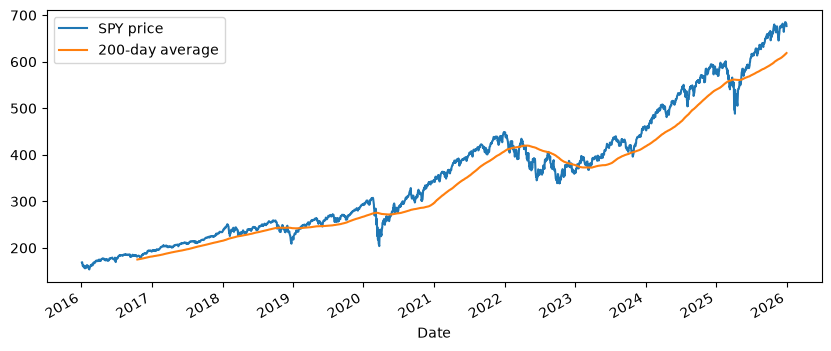

In [15]:
px = prices[A]
ma = px.rolling(WINDOW).mean()    # hint: use WINDOW, not the number 200

px.plot(label=f"{A} price", figsize=(10, 4))
ma.plot(label=f"{WINDOW}-day average")
plt.legend();

**Look for:**
- The average starts about 200 days late. It needs 200 days of history before it exists.
- It **lags**. It only turns down after the price has already been falling for a while. Find a big drop (early 2020 or 2022): how far had the price already fallen before it crossed below the line? That lag is what the rule costs you.

## Step 3: Turn it into a signal
**What:** a column of 1s and 0s. **1** means price is above the average (hold). **0** means below (cash).

**Why:** a backtest needs to know, for every day, whether you're in or out.

`px > ma` gives True or False for each day, and `.astype(int)` turns True into 1 and False into 0.

The last line drops the first 199 days, where the average doesn't exist yet. That way the rule and buy-and-hold are compared over exactly the same days.

In [16]:
signal = (px > ma).astype(int)     # hint: hold when the price is ABOVE the average
valid = ma.notna()                   # True on days where the average exists
signal, r = signal[valid], rets[A][valid]
signal.value_counts()

SPY
1    1926
0     389
Name: count, dtype: int64

**Look for:** how many 1s vs 0s. If the asset went up over the decade, you should see mostly 1s. If you're in cash more than half the time, the asset spent a lot of time going down.

## Step 4: Don't trade on information you don't have yet
**What:** shift the signal forward by one day.

**Why:** Monday's signal uses Monday's closing price. You only know that price at 4pm Monday, after Monday's return has already happened. So Monday's signal can only decide what you hold on **Tuesday**.

Skip the shift and your backtest trades Monday's return using Monday's close. That's looking into the future, and it makes almost any rule look amazing. This is called **look-ahead bias**, and it's the most common bug in backtesting.

`.shift(1)` moves every value down one row. `.fillna(0)` says we start the first day in cash. The second half of the cell finds the first day the signal flips and shows the days around it.

In [17]:
position = signal.shift(1).fillna(0)

check = pd.DataFrame({"price": px[valid], "average": ma[valid], "signal": signal, "position": position})
i = signal.diff().fillna(0).ne(0).values.argmax()    # row number of the first flip
check.iloc[i - 2 : i + 3]

,price,average,signal,position
Date,,,,
2018-10-09,254.976349,243.085241,1,1.0
2018-10-10,246.903015,243.148424,1,1.0
2018-10-11,241.464584,243.185817,0,1.0
2018-10-12,244.818130,243.239407,1,0.0
2018-10-15,243.443008,243.283714,1,1.0


**Look for:** on the day `signal` flips, `position` still has the old value. It flips one day later. That one-day delay is the whole point.

## Step 5: Strategy returns and the equity curve
**What:** on days you hold (position = 1) you earn the asset's return. On days you're in cash (position = 0) you earn nothing. So the strategy's daily return is just

$$\text{strategy return} = \text{position} \times \text{asset return}$$

The **equity curve** shows what $1 grows to: compound the daily returns with `(1 + returns).cumprod()`. Fill in the strategy return.

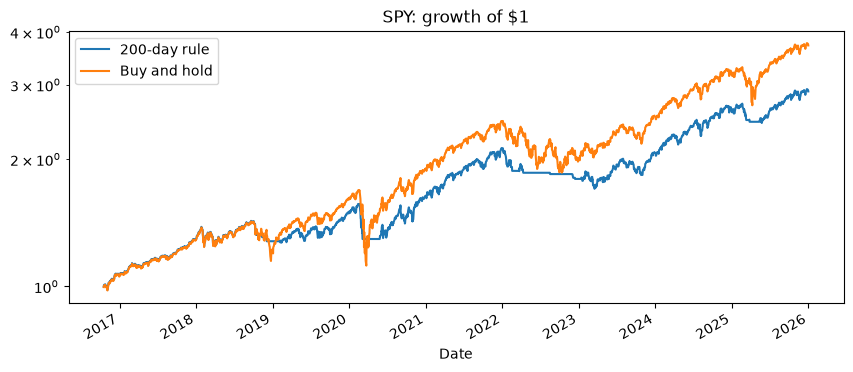

In [18]:
strat = position * r       # hint: position times the asset's return (r)

equity = pd.DataFrame({
    f"{WINDOW}-day rule": (1 + strat).cumprod(),
    "Buy and hold": (1 + r).cumprod(),
})
equity.plot(title=f"{A}: growth of $1", figsize=(10, 4), logy=True);

**Look for:**
- **Flat stretches** in the rule's line are when you were in cash. Did they line up with crashes (good) or with the asset going up without you (bad)?
- The y-axis is a log scale, so a 50% drop looks the same size whether it happened at \$1 or at \$10.

## Step 6: The scorecard
Three numbers to judge any strategy:

| Number | What it means |
|---|---|
| **Sharpe** | Return per unit of risk, from Week 4. To keep it simple, cash earns 0 here and we skip the T-bill |
| **Max drawdown** | The worst fall from a peak. -0.50 means at some point you were down 50% from your best. This is the number that makes people quit a strategy |
| **Total return** | What \$1 turned into, minus the \$1. 2.0 means you tripled your money |
| **Trades** | How many times you bought or sold. Every trade costs money (Step 8) |

`position.diff().abs()` is 1 on each day you bought or sold and 0 otherwise, so adding it up counts the trades. Just run this cell.

In [19]:
def scorecard(daily):
    equity = (1 + daily).cumprod()
    return pd.Series({
        "Sharpe": daily.mean() / daily.std() * np.sqrt(252),
        "Max drawdown": (equity / equity.cummax() - 1).min(),
        "Total return": equity.iloc[-1] - 1,
    })

score = pd.DataFrame({"Rule": scorecard(strat), "Buy and hold": scorecard(r)})
score.loc["Trades"] = [position.diff().abs().sum(), 1]
score.round(2)

,Rule,Buy and hold
Sharpe,1.02,0.87
Max drawdown,-0.20,-0.34
Total return,1.89,2.72
Trades,49.00,1.00


**Look for:** the usual result is that the rule wins on max drawdown and loses on total return: less pain, less gain. The Sharpe tells you which is the better deal per unit of risk.

> **Try this:** go back to Step 4, change `shift(1)` to `shift(0)` (no delay), and rerun Steps 4 to 6. Watch what happens to the Sharpe. That jump is pure look-ahead bias. **Change it back to `shift(1)` before you move on.**

**What happened with `shift(0)`:** [FILL IN]

## Step 7: Package it up and run asset B
You've built the whole backtest one line at a time. `rule_returns` below is exactly Steps 2 to 5 in one place, so you can rerun it on any asset or window in one line. Read through it: every line should look familiar. It has one new input, `cost_bps`, which you'll use in Step 8.

- `run_rule` gives the rule's scorecard.
- `buy_and_hold` gives the buy-and-hold scorecard over the same days.

**Check your work:** the `A` columns below should match your Step 6 table exactly. If they don't, something in Steps 2 to 5 is off.

In [20]:
def rule_returns(px, window=WINDOW, cost_bps=0):
    r = px.pct_change()
    ma = px.rolling(window).mean()                     # Step 2
    signal = (px > ma).astype(int)                     # Step 3
    valid = ma.notna()
    signal, r = signal[valid], r[valid]
    position = signal.shift(1).fillna(0)               # Step 4
    trades = position.diff().abs().fillna(0)
    strat = position * r - trades * cost_bps / 10000   # Step 5, minus costs (Step 8)
    return strat, r, trades.sum()

def run_rule(px, window=WINDOW, cost_bps=0):
    strat, r, n_trades = rule_returns(px, window, cost_bps)
    return pd.concat([scorecard(strat), pd.Series({"Trades": n_trades})])

def buy_and_hold(px, window=WINDOW):
    strat, r, n_trades = rule_returns(px, window)
    return pd.concat([scorecard(r), pd.Series({"Trades": 1})])

pd.DataFrame({
    f"{A} rule": run_rule(prices[A]), f"{A} buy & hold": buy_and_hold(prices[A]),
    f"{B} rule": run_rule(prices[B]), f"{B} buy & hold": buy_and_hold(prices[B]),
}).round(2)

,SPY rule,SPY buy & hold,RSP rule,RSP buy & hold
Sharpe,1.02,0.87,0.61,0.68
Max drawdown,-0.20,-0.34,-0.24,-0.39
Total return,1.89,2.72,0.82,1.75
Trades,49.00,1.00,67.00,1.00


Now the equity curves for both assets side by side:

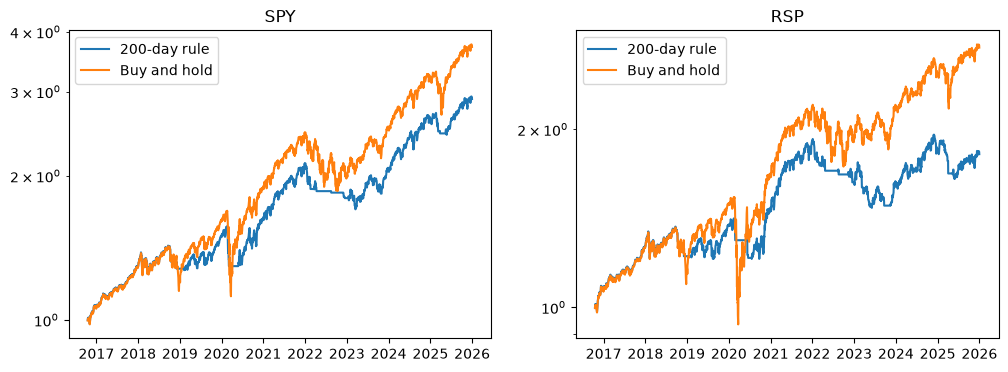

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, t in zip(axes, [A, B]):
    strat_t, r_t, _ = rule_returns(prices[t])
    ax.plot((1 + strat_t).cumprod(), label=f"{WINDOW}-day rule")
    ax.plot((1 + r_t).cumprod(), label="Buy and hold")
    ax.set(title=t, yscale="log")
    ax.legend()

**Look for:** does the rule help on both assets or only one? Trend rules tend to help most on assets with long, deep crashes and do little on steady ones.

## Step 8: The cost of reality
Every time you buy or sell, you pay something: the bid-ask spread, fees, the price moving against you as you trade. We'll charge a flat cost per trade in **basis points (bp)**:

$$1 \text{ bp} = 0.01\% = 0.0001$$

So 10 bp on a \$10,000 trade is \$10. In `rule_returns`, the line `trades * cost_bps / 10000` takes that bite out of every day you trade.

Rough real-world costs: a big ETF like SPY or a large stock is around 1 to 5 bp. Small stocks and crypto can run 10 to 50 bp.

**Before you run it:** look at your trade count from Step 7. Do you think 20 bp per trade will matter much?

**My guess:** [FILL IN]

In [22]:
costs = [0, 5, 10, 20, 50]

for t in [A, B]:
    cost_table = pd.DataFrame({f"{c} bp": run_rule(prices[t], cost_bps=c) for c in costs})
    cost_table["Buy and hold"] = buy_and_hold(prices[t])
    print(t)
    display(cost_table.round(2))

SPY


,0 bp,5 bp,10 bp,20 bp,50 bp,Buy and hold
Sharpe,1.02,1.00,0.98,0.93,0.80,0.87
Max drawdown,-0.20,-0.21,-0.22,-0.23,-0.28,-0.34
Total return,1.89,1.82,1.76,1.62,1.26,2.72
Trades,49.00,49.00,49.00,49.00,49.00,1.00


RSP


,0 bp,5 bp,10 bp,20 bp,50 bp,Buy and hold
Sharpe,0.61,0.58,0.54,0.48,0.30,0.68
Max drawdown,-0.24,-0.25,-0.26,-0.28,-0.35,-0.39
Total return,0.82,0.76,0.70,0.59,0.30,1.75
Trades,67.00,67.00,67.00,67.00,67.00,1.00


**Find the threshold:** the cost where the rule's Sharpe drops below buy and hold's. That's where the edge vanishes. If the rule's Sharpe is already below buy and hold at 0 bp, write "no edge even before costs."

**Threshold for A:** Between 20bp and 50bp where 20 is 0.93 > 0.87 and 50 is 0.8 < 0.87.

**Threshold for B:** No edge even before costs.

## Step 9: Could it just be luck? (required)
**The idea:** take your real daily returns and shuffle them into a random order. Same returns, same average, same volatility, but any real trends are destroyed. Run the rule on that fake price history, and do it 500 times.

If the rule is picking up real trends, it should do better on the real data than on most of the shuffled versions. If your real Sharpe lands in the middle of the fake ones, the rule did about what luck would do.

Shuffling doesn't change buy and hold at all (same returns, different order), so the only thing being tested is whether the rule's timing works.

Nothing to fill in here, just run it. It takes a few seconds.

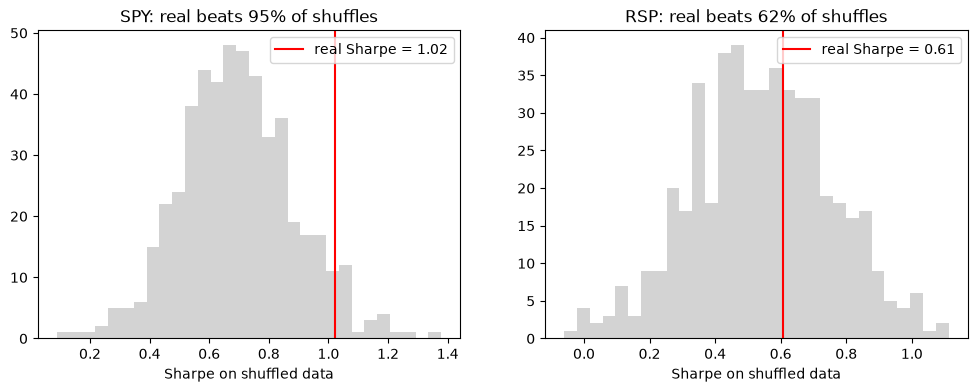

In [23]:
rng = np.random.default_rng(0)    # fixed seed, so you get the same answer every run
N = 500

def fake_sharpes(px):
    real_rets = px.pct_change().dropna().values
    out = []
    for _ in range(N):
        fake_px = pd.Series(np.cumprod(1 + rng.permutation(real_rets)))   # shuffle, then rebuild prices
        out.append(run_rule(fake_px)["Sharpe"])
    return np.array(out)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, t in zip(axes, [A, B]):
    fake = fake_sharpes(prices[t])
    real = run_rule(prices[t])["Sharpe"]
    ax.hist(fake, bins=30, color="lightgray")
    ax.axvline(real, color="red", label=f"real Sharpe = {real:.2f}")
    ax.set(title=f"{t}: real beats {(fake < real).mean():.0%} of shuffles", xlabel="Sharpe on shuffled data")
    ax.legend()

**How to read it:** the title gives the share of shuffled runs your real Sharpe beat.
- **Above 95%:** the real result beats nearly every shuffle. Some evidence the rule found real trends.
- **50% to 95%:** weak. You can't rule out luck.
- **Around 50% or below:** no evidence the rule does anything.

**My result:** SPY beat around 95% of shuffles, whereas RSP beats 62% so its weak and we can't rule out luck.

## Step 10: Is 200 special? Vary the window
200 days is a famous number, but nobody proved it's the right one. If the rule really captures trends, nearby windows like 150 or 250 should work about as well. If 200 works and 180 and 220 fall apart, the 200-day result was probably a fluke.

> A real edge fades gradually as you change the window. An over-fitted one falls apart.

**Before you run anything, predict:** with a short window like 50 days, will the rule trade more or less than with 200? Will it get out of a crash earlier or later?

**My prediction:** With a shorter window the rule will make more trades and follow the Ups and Downs of the asset more closely. It should get out of a crash earilier but fall harder in the crash.

### Part 1: one window by hand
Go back to Step 1, change `WINDOW = 200` to `WINDOW = 50`, then **Run All**. Look at:
- the Step 2 chart: how closely does the average hug the price now?
- the Step 6 scorecard: how many trades now?

Then **set it back to 200** and Run All again.

### Part 2: many windows at once
This runs the rule once for each window in the list. Read `{w: ... for w in windows}` as "for each window `w` in the list, run the rule with that window." Fill in the window for asset A (asset B is done for you), and add any other windows you want to try.

In [24]:
windows = [50, 100, 150, 200, 250, 300]    # <- add more if you like

sens_A = pd.DataFrame({w: run_rule(prices[A], window=w) for w in windows}).T
sens_B = pd.DataFrame({w: run_rule(prices[B], window=w) for w in windows}).T
sens_A.round(2)

,Sharpe,Max drawdown,Total return,Trades
50,0.87,-0.20,1.35,151.0
100,0.98,-0.18,1.74,81.0
150,0.90,-0.21,1.54,63.0
200,1.02,-0.20,1.89,49.0
250,0.91,-0.22,1.58,51.0
300,0.87,-0.23,1.54,31.0


In [25]:
sens_B.round(2)

,Sharpe,Max drawdown,Total return,Trades
50,0.69,-0.19,1.01,155.0
100,0.48,-0.30,0.59,127.0
150,0.41,-0.26,0.47,93.0
200,0.61,-0.24,0.82,67.0
250,0.47,-0.27,0.56,53.0
300,0.40,-0.30,0.44,65.0


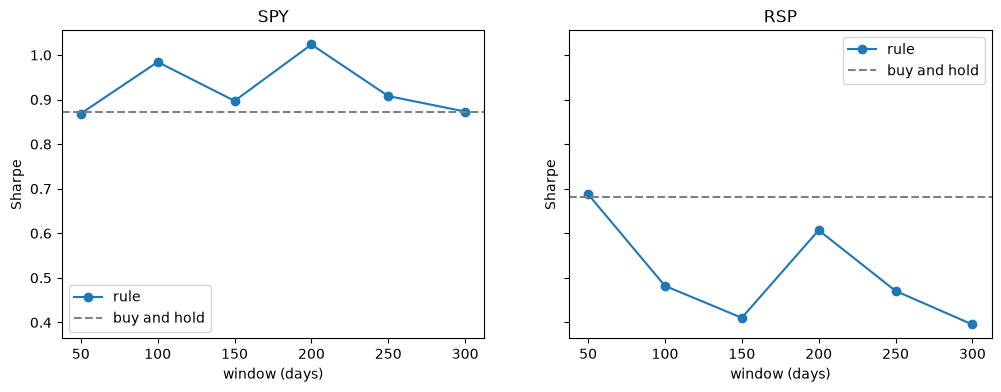

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, t, s in zip(axes, [A, B], [sens_A, sens_B]):
    ax.plot(s.index, s["Sharpe"], marker="o", label="rule")
    ax.axhline(buy_and_hold(prices[t])["Sharpe"], color="gray", linestyle="--", label="buy and hold")
    ax.set(title=t, xlabel="window (days)", ylabel="Sharpe")
    ax.legend()

**Look for:**
- **Trades column:** was your prediction right? Shorter windows hug the price more closely, so they flip in and out more often.
- **Shape of the Sharpe line:** a smooth hill or a fairly flat line means the result doesn't hinge on one magic number. A jagged line that spikes at one window means it does.
- **Where 200 sits:** is it the best window, or just one of many that work about the same?

Longer windows need more history before they start, so each row covers slightly fewer days. That's fine for this comparison.

## The Paragraph
> **After applying costs and the random data check, did the 200-day rule actually survive on either asset?**

Hit these:
- Before costs: did the rule beat buy and hold on Sharpe? On max drawdown?
- Costs: at how many bp did the edge vanish, and is that above or below a realistic cost for your assets?
- Luck: what share of the shuffled runs did your real Sharpe beat?
- Window: did nearby windows give similar results, or was 200 special?

The 200-day rule barely survived on SPY and failed on RSP. Before costs, it beat buy and hold on Sharpe for SPY (1.02 vs 0.87) but not for RSP (0.61 vs 0.68). It cut max drawdown on both (SPY -20% vs -34%; RSP -24% vs -39%), but it gave up a lot of return (SPY 189% vs 272%; RSP 82% vs 175%). So it reduces risk rather than adding profit. Costs hurt RSP most: its Sharpe fell from 0.61 to 0.30 at 50 bp, and it never beat buy and hold on Sharpe, even at 0 bp. For SPY, I estimate the Sharpe edge disappears at about 30 bp (extrapolated, not measured). That is far above a realistic cost of 1 to 2 bp. The shuffle test showed the same split. SPY's real Sharpe beat 95% of shuffled runs, which is borderline significant. RSP's beat only 62%, which is no better than chance. Nearby windows agreed. On SPY, every window from 50 to 300 had a Sharpe of 0.87 to 1.02, so 200 was not special. On RSP, 200 was an isolated bump between weaker neighbors. Overall, the rule gives a modest edge on SPY and little beyond lower drawdowns on RSP.

---
**Done?** Restart the kernel and **Run All** to check everything runs top to bottom, then commit
(navigate into your project folder in the terminal first):

```bash
git add .
git commit -m "Week 8: systematic rule"
git push
```